In [1]:
# ==========#Code by Dr. Rahul M. Dhokane, PRAVARA SVIT, NASHIK============
# Complete Python Script: Email Spam Binary Classification (KNN vs SVM)
# Dataset: emails.csv (Kaggle)
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# ------------------------------------------------------------------------------
# STEP 1: Load Dataset
# ------------------------------------------------------------------------------
print("Loading emails.csv dataset...")
df = pd.read_csv("emails.csv")

print(f"Dataset Dimensions: {df.shape}")
print(df.head())

Loading emails.csv dataset...
Dataset Dimensions: (5172, 3002)
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]

In [2]:
# ------------------------------------------------------------------------------
# STEP 2: Data Preprocessing
# ------------------------------------------------------------------------------
# Check for null values
print(f"Total Missing Values: {df.isnull().sum().sum()}")

# Drop unique identifier column if present
if "Email No." in df.columns:
    df = df.drop(columns=["Email No."])

# Separate Features (X) and Target Label (y)
# Target state: 0 = Normal State (Not Spam), 1 = Abnormal State (Spam)
X = df.iloc[:, :-1]  # 3,000 word frequency features
y = df.iloc[:, -1]  # Binary label (Prediction)

print("\nClass Distribution:")
print(
    y.value_counts().rename(
        {0: "Normal State (Not Spam)", 1: "Abnormal State (Spam)"}
    )
)

Total Missing Values: 0

Class Distribution:
Prediction
Normal State (Not Spam)    3672
Abnormal State (Spam)      1500
Name: count, dtype: int64


In [3]:
# ------------------------------------------------------------------------------
# STEP 3: Train-Test Split and Feature Scaling
# ------------------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Standardize features (Mean = 0, Std = 1) for distance and kernel calculations
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [4]:
# ------------------------------------------------------------------------------
# STEP 4: K-Nearest Neighbors (KNN) Classifier
# ------------------------------------------------------------------------------
print("\nTraining K-Nearest Neighbors Classifier...")
knn_model = KNeighborsClassifier(n_neighbors=5, metric="minkowski", p=2)
knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)

acc_knn = accuracy_score(y_test, y_pred_knn)
prec_knn = precision_score(y_test, y_pred_knn)
rec_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)


Training K-Nearest Neighbors Classifier...


In [5]:
# ------------------------------------------------------------------------------
# STEP 5: Support Vector Machine (SVM) Classifier
# ------------------------------------------------------------------------------
print("Training Support Vector Machine Classifier...")
svm_model = SVC(kernel="rbf", C=1.0, random_state=42)
svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

acc_svm = accuracy_score(y_test, y_pred_svm)
prec_svm = precision_score(y_test, y_pred_svm)
rec_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)

Training Support Vector Machine Classifier...


In [6]:
# ------------------------------------------------------------------------------
# STEP 6: Performance Evaluation & Comparison
# ------------------------------------------------------------------------------
print("\n==================================================================")
print("                    PERFORMANCE METRICS SUMMARY                   ")
print("==================================================================")

results_df = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
        "KNN (k=5)": [acc_knn, prec_knn, rec_knn, f1_knn],
        "SVM (RBF Kernel)": [acc_svm, prec_svm, rec_svm, f1_svm],
    }
)

print(results_df.to_string(index=False))

print("\n--- Detailed Classification Report: KNN ---")
print(
    classification_report(
        y_test,
        y_pred_knn,
        target_names=["Normal (Not Spam)", "Abnormal (Spam)"],
    )
)

print("\n--- Detailed Classification Report: SVM ---")
print(
    classification_report(
        y_test,
        y_pred_svm,
        target_names=["Normal (Not Spam)", "Abnormal (Spam)"],
    )
)



                    PERFORMANCE METRICS SUMMARY                   
   Metric  KNN (k=5)  SVM (RBF Kernel)
 Accuracy   0.833816          0.930435
Precision   0.643498          0.983051
   Recall   0.956667          0.773333
 F1-Score   0.769437          0.865672

--- Detailed Classification Report: KNN ---
                   precision    recall  f1-score   support

Normal (Not Spam)       0.98      0.78      0.87       735
  Abnormal (Spam)       0.64      0.96      0.77       300

         accuracy                           0.83      1035
        macro avg       0.81      0.87      0.82      1035
     weighted avg       0.88      0.83      0.84      1035


--- Detailed Classification Report: SVM ---
                   precision    recall  f1-score   support

Normal (Not Spam)       0.91      0.99      0.95       735
  Abnormal (Spam)       0.98      0.77      0.87       300

         accuracy                           0.93      1035
        macro avg       0.95      0.88      0.91    

Text(145.38563368055554, 0.5, 'Actual Class')

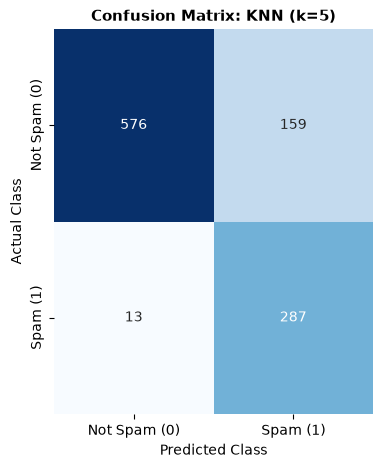

In [7]:
# ------------------------------------------------------------------------------
# STEP 7: Visualizations (Confusion Matrices & Bar Chart)
# ------------------------------------------------------------------------------
plt.figure(figsize=(14, 5))

# Plot 1: Confusion Matrix - KNN
plt.subplot(1, 3, 1)
cm_knn = confusion_matrix(y_test, y_pred_knn)
sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Spam (0)", "Spam (1)"],
    yticklabels=["Not Spam (0)", "Spam (1)"],
    cbar=False,
)
plt.title("Confusion Matrix: KNN (k=5)", fontsize=11, fontweight="bold")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

Text(145.38563368055554, 0.5, 'Actual Class')

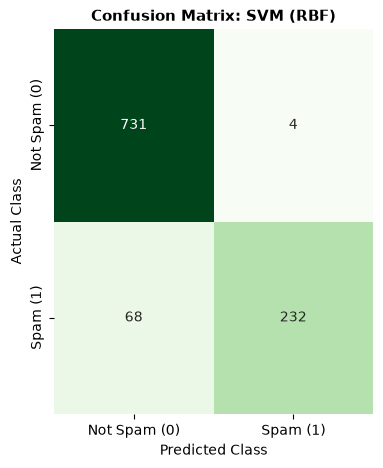

In [8]:
# Plot 2: Confusion Matrix - SVM
plt.figure(figsize=(14, 5))
plt.subplot(1, 3, 1)
cm_svm = confusion_matrix(y_test, y_pred_svm)
sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Not Spam (0)", "Spam (1)"],
    yticklabels=["Not Spam (0)", "Spam (1)"],
    cbar=False,
)
plt.title("Confusion Matrix: SVM (RBF)", fontsize=11, fontweight="bold")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

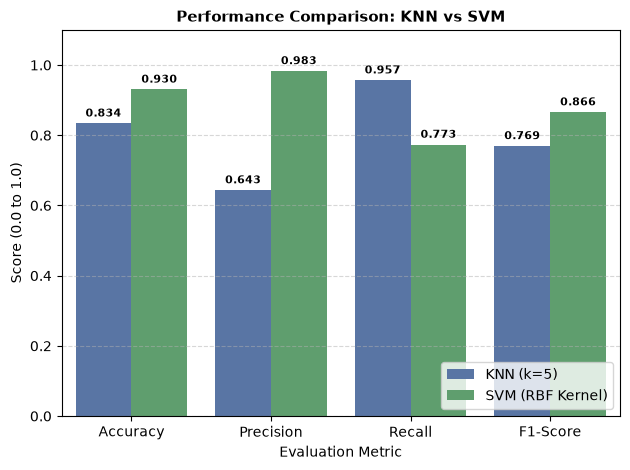

In [9]:
# Plot 3: Performance Metrics Comparison Bar Chart
plt.subplot(1, 1, 1)
results_melted = results_df.melt(
    id_vars="Metric", var_name="Model", value_name="Score"
)

ax = sns.barplot(
    data=results_melted,
    x="Metric",
    y="Score",
    hue="Model",
    palette=["#4C72B0", "#55A868"],
)

plt.title(
    "Performance Comparison: KNN vs SVM", fontsize=11, fontweight="bold"
)
plt.ylabel("Score (0.0 to 1.0)")
plt.xlabel("Evaluation Metric")
plt.ylim(0.0, 1.1)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(loc="lower right")

# Add exact text labels above each bar
for container in ax.containers:
    ax.bar_label(
        container, fmt="%.3f", padding=3, fontsize=8, fontweight="bold"
    )

plt.tight_layout()
plt.show()